# Salari nel settore tech italiano: un'analisi statistica

## Scopo dell'analisi

L'Italia ha un mercato tech in crescita, ma quanto guadagnano davvero i professionisti del settore? E soprattutto: **quali fattori determinano le differenze salariali?**

In questo notebook si risponde a quattro domande concrete, usando i dati e i test statistici appropriati:

1. **Quanto conta l'esperienza?** - Un senior guadagna davvero molto più di un junior? Quanto "pesa" ogni anno in più?
2. **Dove conviene lavorare?** - Esiste un divario Nord-Sud anche nel tech?
3. **Esistono disuguaglianze strutturali?** - C'è un gender pay gap? Persiste anche a parità di esperienza?
4. **Cosa fa davvero la differenza?** - Tra esperienza, regione, azienda e modalità di lavoro, quale fattore influisce maggiormente?

## Struttura del notebook

| Sezione | Contenuto | Domande guida |
|---------|-----------|---------------|
| **1. Panoramica** | Statistiche descrittive e distribuzione | Come sono distribuiti i salari? |
| **2. Analisi Univariate** | Impatto di ogni singolo fattore | Esperienza, regione, ruolo, dimensione azienda, gender, education, industry |
| **3. Analisi Incrociate** | Interazione tra fattori | Il gap Nord-Sud cambia con la seniority? |
| **4. Chi Quadro** | Relazioni tra variabili categoriche | Remote e regione sono indipendenti? |
| **5. Regressione** | Modello multivariato | Qual è l'effetto netto di ogni fattore? |
| **6. Riepilogo** | Sintesi e conclusioni | Risposte alle 4 domande guida |

## Nota metodologica

Per ogni analisi si segue uno schema consolidato:
- **Cosa si analizza**: quale analisi effettuare e su quali dati
- **Perché**: a quale domanda si vuole rispondere
- **Quale test e come funziona**: spiegazione accessibile del metodo statistico
- **Come leggere i risultati**: guida all'interpretazione dei risultati

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

from huggingface_hub.utils import logging as hf_logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import tukey_hsd
import seaborn as sns
from statsmodels.formula.api import ols

from salaries_analysis.data import (
    describe_complete,
    describe_groups,
    feature_engineering,
    load_salaries,
)
from salaries_analysis.statistics import (
    adjust_pvalues,
    check_anova_assumptions,
    chi2_test,
    cohens_d,
    factorial_anova,
    oneway_anova,
    ttest,
)
from salaries_analysis.visualization import STYLE_PATH, plot_heatmap, plot_salary_boxplot

hf_logging.set_verbosity_error()

In [2]:
# Configurazione display pandas
pd.set_option("display.max_columns", None)

# Configurazione grafici
sns.set_theme(context="notebook", style="whitegrid", palette="deep")
plt.style.use(style=STYLE_PATH)

## Data Catalog

### Fonte dei dati

Il dataset proviene da [HuggingFace - datapizza-ai-lab/salaries](https://huggingface.co/datasets/datapizza-ai-lab/salaries), una raccolta di self-reported salaries nel settore tech italiano. I dati sono stati raccolti tramite survey online tra il 2024 e il 2025. Come tutti i dati self-reported, vanno interpretati con consapevolezza dei possibili bias (autoselezione, arrotondamento, campione non rappresentativo).

### Colonne originali

| Colonna | Tipo | Descrizione |
|---------|------|-------------|
| `jobTitle` | categorica | Ruolo professionale (es. data_engineer, backend_developer) |
| `monthsOfExperience` | numerica | Mesi di esperienza lavorativa |
| `educationType` | categorica | Titolo di studio (laurea triennale, magistrale, PhD, etc.) |
| `companyIndustry` | categorica | Settore dell'azienda |
| `companySize` | categorica | Dimensione dell'azienda (fasce: 1-10, 11-50, ..., 5001+) |
| `province` | categorica | Provincia di lavoro |
| `workMode` | categorica | Modalità di lavoro (remote, hybrid, onsite) |
| `technologies` | testo | Stack tecnologico utilizzato |
| `salary` | numerica | RAL annua in euro (€) |
| `age` | numerica | Età del rispondente |
| `gender` | categorica | Genere (male, female, other) |
| `submittedAt` | datetime | Data di compilazione del survey |

In [3]:
# Revisione del dataset fissata in salaries_analysis.data.dataset.DATASET_REVISION
df_raw = load_salaries()
df_raw.head()

,jobTitle,monthsOfExperience,educationType,companyIndustry,companySize,province,workMode,technologies,salary,age,gender,aiUsageFrequency,aiTechnologies,aiTaskTypes,aiUpdateSources,admiredTechnologies,editor,rating,valid,submittedAt
0,ai_engineer,19,Master's Degree,tecnologia_ict,51-200,Milano,remote,"[Python, Datapizza AI, AWS, GenAI, PostgreSQL]",32000.0,25.0,male,5.0,"[gemini, cursor, chat_gpt]","[coding, study_tutoring]","[x_twitter, newsletter, reddit, linkedin, offi...","[Typescript, Datapizza AI]",cursor,5.0,True,2025-12-15 18:53:06.587
1,product_manager,6,Master's Degree,tecnologia_ict,11-50,Milano,hybrid,"[SQL, Jira]",35000.0,26.0,female,5.0,"[claude, claude_code]",[coding],[linkedin],None,vscode,NaN,True,2025-12-16 08:34:28.793
2,data_engineer,3,Master's Degree,consulenza_servizi_professionali,51-200,Milano,hybrid,"[Python, Scikit-learn, Keras, TensorFlow, PyTo...",22000.0,25.0,male,NaN,"[chat_gpt, github_copilot, gemini, claude]","[coding, doc_analysis, brainstorming, translat...","[x_twitter, reddit, hugging_face, newsletter, ...","[Python, SQL, Markdown, Machine/Deep Learning,...",vscode,5.0,True,2025-12-16 08:35:18.781
3,cloud_infrastructure,102,Bachelor's Degree,consulenza_servizi_professionali,5001+,Milano,remote,"[Microsoft Azure, AWS]",55000.0,34.0,male,3.0,None,None,None,None,None,NaN,True,2025-12-16 08:36:33.936
4,backend_developer,240,Bachelor's Degree,tecnologia_ict,11-50,Varese,onsite,"[Python, C#, Oracle, Linux]",58000.0,48.0,male,4.0,"[claude, chat_gpt]","[coding, study_tutoring]",[official_blogs],[.NET code],vscode,4.0,True,2025-12-16 08:38:01.168


### Colonne derivate (feature engineering)

| Colonna | Derivata da | Logica |
|---------|-------------|--------|
| `region` | `province` | Mappatura provincia → regione |
| `macro_region` | `region` | Raggruppamento in Nord, Centro, Sud |
| `yearsOfExperience` | `monthsOfExperience` | Conversione mesi → anni |
| `experience` | `yearsOfExperience` | Fasce: junior (≤2), middle (3-5), senior (>5) |
| `yearSubmittedAt` | `submittedAt` | Anno di compilazione |

In [4]:
df = feature_engineering(df=df_raw)
df.head()

,jobTitle,monthsOfExperience,educationType,companyIndustry,companySize,province,workMode,technologies,salary,age,gender,aiUsageFrequency,aiTechnologies,aiTaskTypes,aiUpdateSources,admiredTechnologies,editor,rating,valid,submittedAt,region,macro_region,yearsOfExperience,experience,yearSubmittedAt
0,ai_engineer,19,Master's Degree,tecnologia_ict,51-200,Milano,remote,"[Python, Datapizza AI, AWS, GenAI, PostgreSQL]",32000.0,25.0,male,5.0,"[gemini, cursor, chat_gpt]","[coding, study_tutoring]","[x_twitter, newsletter, reddit, linkedin, offi...","[Typescript, Datapizza AI]",cursor,5.0,True,2025-12-15 18:53:06.587,Lombardia,Nord,1,junior,2025
1,product_manager,6,Master's Degree,tecnologia_ict,11-50,Milano,hybrid,"[SQL, Jira]",35000.0,26.0,female,5.0,"[claude, claude_code]",[coding],[linkedin],None,vscode,NaN,True,2025-12-16 08:34:28.793,Lombardia,Nord,0,junior,2025
2,data_engineer,3,Master's Degree,consulenza_servizi_professionali,51-200,Milano,hybrid,"[Python, Scikit-learn, Keras, TensorFlow, PyTo...",22000.0,25.0,male,NaN,"[chat_gpt, github_copilot, gemini, claude]","[coding, doc_analysis, brainstorming, translat...","[x_twitter, reddit, hugging_face, newsletter, ...","[Python, SQL, Markdown, Machine/Deep Learning,...",vscode,5.0,True,2025-12-16 08:35:18.781,Lombardia,Nord,0,junior,2025
3,cloud_infrastructure,102,Bachelor's Degree,consulenza_servizi_professionali,5001+,Milano,remote,"[Microsoft Azure, AWS]",55000.0,34.0,male,3.0,None,None,None,None,None,NaN,True,2025-12-16 08:36:33.936,Lombardia,Nord,8,senior,2025
4,backend_developer,240,Bachelor's Degree,tecnologia_ict,11-50,Varese,onsite,"[Python, C#, Oracle, Linux]",58000.0,48.0,male,4.0,"[claude, chat_gpt]","[coding, study_tutoring]",[official_blogs],[.NET code],vscode,4.0,True,2025-12-16 08:38:01.168,Lombardia,Nord,20,senior,2025


### Statistiche descrittive e struttura del dataset  
Si segnala la presenza di outlier estremi per `monthsOfExperience` (e di conseguenza per `yearsOfExperience`, che ne è derivata)

In [5]:
df.describe().transpose().round(decimals=4)

,count,mean,std,min,25%,50%,75%,max
monthsOfExperience,26478.0,58.1522,158.5652,1.0,21.0,39.0,72.0,24126.0
salary,26478.0,37967.7745,17811.3575,3000.0,28000.0,35000.0,44000.0,500000.0
age,1069.0,32.1394,7.7645,16.0,27.0,30.0,36.0,95.0
aiUsageFrequency,866.0,3.4665,0.9505,1.0,3.0,4.0,4.0,5.0
rating,596.0,4.6359,0.6271,2.0,4.0,5.0,5.0,5.0
yearsOfExperience,26478.0,4.6418,13.2375,0.0,1.0,3.0,6.0,2010.0
yearSubmittedAt,26478.0,2024.4285,0.5554,2024.0,2024.0,2024.0,2025.0,2026.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26478 entries, 0 to 26477
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   jobTitle             26478 non-null  object 
 1   monthsOfExperience   26478 non-null  int64  
 2   educationType        1234 non-null   object 
 3   companyIndustry      26457 non-null  object 
 4   companySize          24535 non-null  object 
 5   province             26478 non-null  object 
 6   workMode             26478 non-null  object 
 7   technologies         26478 non-null  object 
 8   salary               26478 non-null  float64
 9   age                  1069 non-null   float64
 10  gender               26361 non-null  object 
 11  aiUsageFrequency     866 non-null    float64
 12  aiTechnologies       1051 non-null   object 
 13  aiTaskTypes          1024 non-null   object 
 14  aiUpdateSources      829 non-null    object 
 15  admiredTechnologies  688 non-null   

### Subset utilizzati nel notebook

| Variabile | Filtro | Record | Uso |
|-----------|--------|--------|-----|
| `df_filtered` | `yearsOfExperience` minore o uguale a 60 | Tutti | Analisi generali |
| `df_data` | `jobTitle` contiene "data" o "ai" | Ruoli data/AI | Confronto ruoli data |
| `df_gender` | `gender` in (male, female) | Escluso "other" | Analisi gender pay gap |
| `df_education` | `educationType` non null | Esclusi missing | Analisi istruzione |

In [7]:
# Rimozione outliers per Experience
df_filtered = df.loc[df["yearsOfExperience"] <= 60]

# Subset per ruoli data/AI
df_data = df_filtered.loc[df_filtered["jobTitle"].str.contains("data", case=False) | df_filtered["jobTitle"].str.contains("ai", case=False), :]

# Subset riutilizzati in tutto il notebook
df_gender = df_filtered.loc[df_filtered["gender"].isin(values=["male", "female"])]
df_education = df_filtered.loc[df_filtered["educationType"].notna(), :]

---
# 1. Panoramica Generale

**Cosa si analizza:** la distribuzione complessiva dei salari con statistiche descrittive e grafici.

**Perché:** prima di cercare differenze tra gruppi, è necessario comprendere come sono distribuiti i salari nel loro complesso. Una distribuzione "normale" (a campana) ci dice che la maggior parte dei valori si concentra intorno alla media. Una distribuzione asimmetrica ci dice che c'è una coda lunga in una direzione - e questo influenza la scelta dei test statistici successivi.

**Come leggere i risultati:**
- **Istogramma**: mostra quante persone guadagnano in ciascuna fascia. Se la "gobba" è spostata a sinistra con una coda a destra, significa che pochi guadagnano molto più della media.
- **Boxplot**: il rettangolo contiene il 50% centrale dei dati (dal 25° al 75° percentile). La linea centrale rappresenta la mediana. I punti fuori dai "baffi" sono outlier.
- **Skewness**: indice di assimetria della distribuzione.
  - skew = 0: simmetrica
  - skew > 0: coda a destra (pochi stipendi molto alti) 
  - skew < 0: coda a sinistra
- **Kurtosis**: misura quanto sono "pesanti" le code. Valori alti = più outlier del previsto.

**Distribuzione dei salari:**
- La distribuzione è **asimmetrica positiva** (skewness > 0): coda lunga verso destra
- La **mediana** è inferiore alla media: presenza di outlier alti
- Range tipico: €28k - €44k per la maggior parte dei lavoratori
- Outlier presenti sopra €100k (ruoli executive/senior)

In [8]:
describe_complete(df=df_filtered, column="salary")

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
salary,26477.0,37968.06,17811.63,3000.0,28000.0,35000.0,44000.0,500000.0,7.24,121.04


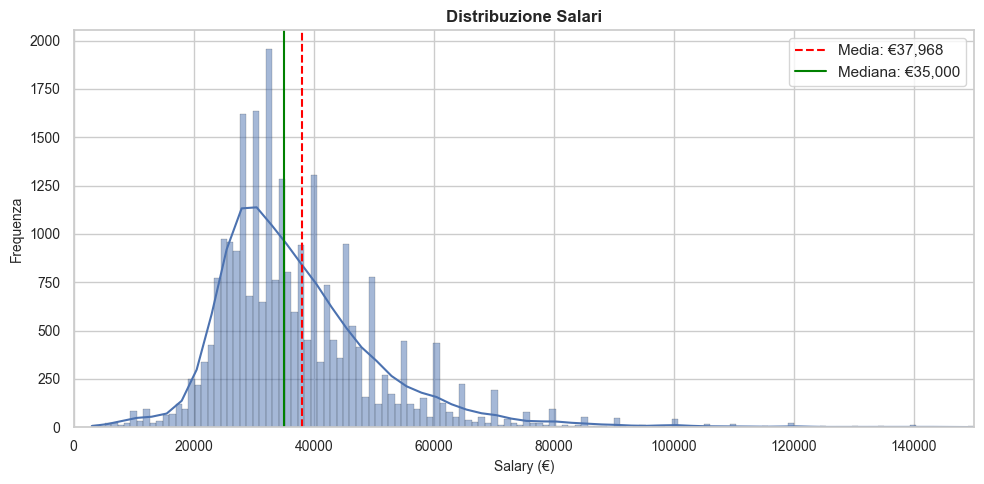

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(data=df_filtered, x="salary", kde=True, ax=ax, edgecolor="black")
ax.axvline(df_filtered["salary"].mean(), color="red", linestyle="--", label=f"Media: €{df_filtered['salary'].mean():,.0f}")
ax.axvline(df_filtered["salary"].median(), color="green", linestyle="-", label=f"Mediana: €{df_filtered['salary'].median():,.0f}")
ax.set_title(label="Distribuzione Salari")
ax.set_xlabel(xlabel="Salary (€)")
ax.set_ylabel(ylabel="Frequenza")
ax.set_xlim(left=0, right=150000)
ax.legend()

plt.tight_layout()
plt.show()

### Interpretazione - Salario  
La maggior parte dei professionisti tech italiani guadagna tra €28k e €44k, ma una minoranza in ruoli senior o executive tira la media verso l'alto. Per questo motivo, nelle analisi successive la mediana sarà spesso un indicatore più affidabile della media.

---
# 2. Analisi Univariate

Si analizza l'impatto di ciascun fattore sul salario, uno alla volta.

## 2.1 Esperienza

**Cosa si analizza:** si confrontano i salari tra tre fasce di esperienza (junior ≤2 anni, middle 3-5 anni, senior >5 anni).

**Perché:** l'esperienza è tipicamente il fattore più influente sul salario. Si vuole rispondere alla domanda *"quanto conta davvero l'esperienza?"*

**Quali test e come funzionano:**

- **ANOVA (Analysis of Variance)**: serve per confrontare le medie di 3 o più gruppi contemporaneamente. L'idea è semplice: se i gruppi fossero uguali, la variabilità *tra* i gruppi sarebbe piccola rispetto alla variabilità *dentro* ogni gruppo. La **F-statistic** misura questo rapporto: più è alta, più i gruppi sono diversi. Il **p-value** ci dice la probabilità di osservare quella differenza per puro caso (se $p < 0.05$, la differenza è statisticamente significativa).

- **Tukey HSD (Honest Significant Difference)**: l'ANOVA ci dice "almeno un gruppo è diverso", ma non *quale*. Tukey HSD confronta tutte le coppie possibili (junior-middle, junior-senior, middle-senior) e ci dice quali differenze sono significative.

- **Cohen's d (effect size)**: il p-value dice se una differenza esiste, ma non quanto è *grande*. Cohen's d misura la dimensione dell'effetto in unità di deviazione standard. Regola pratica: 
  - d < 0.2: trascurabile
  -  0.2 < d < 0.5: piccolo
  - 0.5 < d < 0.8: medio
  - d > 0.8: grande

- **Welch ANOVA**: variante dell'ANOVA che non richiede varianze uguali tra i gruppi. Si usa quando il test di Levene indica varianze non omogenee, come accade in tutti i confronti salariali di questo notebook.

**Nota sulle assunzioni:** l’ANOVA assume normalità dei dati e omogeneità delle varianze. Con campioni grandi (n >= 30 per gruppo), il test è robusto a violazioni di normalità per il Teorema del Limite Centrale. L'omogeneità delle varianze invece non è garantita dalla numerosità: per questo prima del test si verificano le assunzioni e, se Levene le rifiuta, si usa la Welch ANOVA.

I boxplot mostrano una chiara progressione salariale per fascia di esperienza. La correlazione tra anni di esperienza e salario è **moderata**.

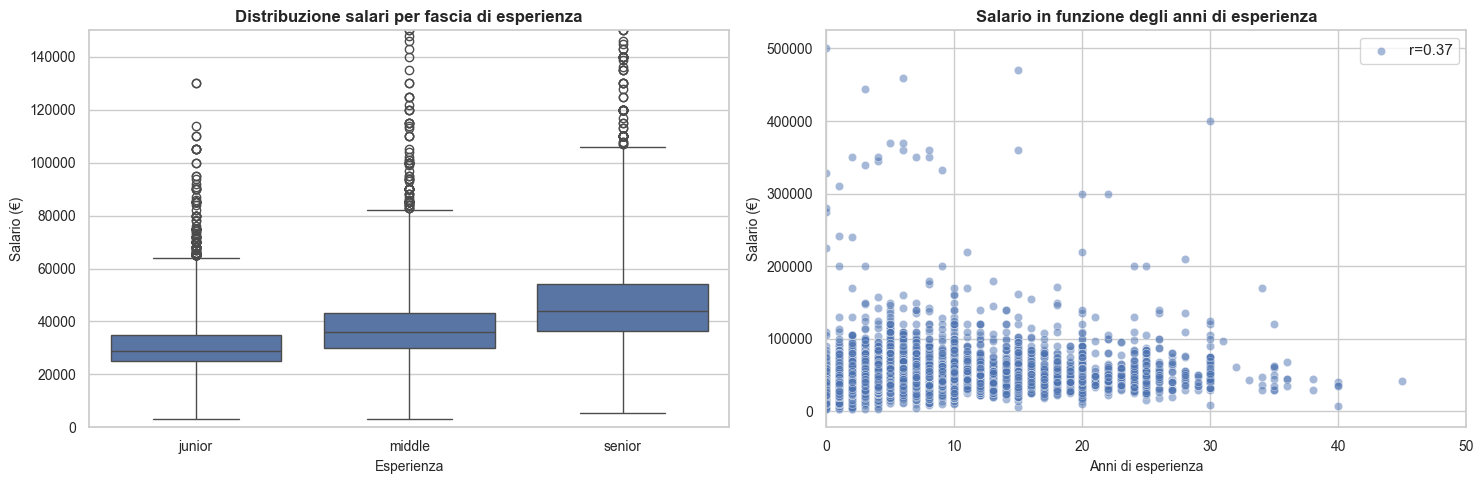

In [10]:
statistic, p_value = stats.pearsonr(x=df_filtered["yearsOfExperience"], y=df_filtered["salary"])

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

sns.boxplot(data=df_filtered, x="experience", y="salary", order=["junior", "middle", "senior"], whis=3, ax=axes[0])
axes[0].set_title("Distribuzione salari per fascia di esperienza")
axes[0].set_xlabel("Esperienza")
axes[0].set_ylabel("Salario (€)")
axes[0].set_ylim(0, 150000)

sns.scatterplot(data=df_filtered, x="yearsOfExperience", y="salary", alpha=0.5, label=f"r={statistic:.2f}", ax=axes[1])
axes[1].set_title("Salario in funzione degli anni di esperienza")
axes[1].set_xlabel("Anni di esperienza")
axes[1].set_ylabel("Salario (€)")
axes[1].set_xlim(0, 50)

plt.tight_layout()
plt.show()

Le varianze non sono omogenee (Levene), quindi si usa la **Welch ANOVA**, che conferma differenze **altamente significative** (F≈1900, p<0.001)

In [11]:
# Test statistici - Esperienza
junior_salaries = df_filtered.loc[df_filtered["experience"] == "junior", "salary"]
middle_salaries = df_filtered.loc[df_filtered["experience"] == "middle", "salary"]
senior_salaries = df_filtered.loc[df_filtered["experience"] == "senior", "salary"]
experience_groups = [junior_salaries, middle_salaries, senior_salaries]

# Verifica assunzioni
check_anova_assumptions(
    groups=experience_groups, labels=["junior", "middle", "senior"], label="Esperienza vs Salario",
).print_report()
print()

# Welch ANOVA (non assume varianze omogenee)
anova_experience = oneway_anova(
    groups=experience_groups, label="Esperienza vs Salario", equal_var=False,
)
print("Salari medi per fascia di esperienza:")
print(f"Junior {junior_salaries.mean():,.0f} | Middle {middle_salaries.mean():,.0f} | Senior {senior_salaries.mean():,.0f}")
anova_experience.print_report()

Verifica assunzioni - Esperienza vs Salario
Normalità (Shapiro-Wilk, α=0.05):
  junior (n=10979): W=0.5883, p=5.26e-76 - non normale
  middle (n=8229): W=0.7220, p=5.66e-68 - non normale
  senior (n=7269): W=0.6487, p=1.05e-72 - non normale
Omoschedasticità (Levene, α=0.05):
  F=295.03, p=1.89e-127 - varianze non omogenee
Raccomandazione: Normalità violata, ma tutti i gruppi hanno n >= 30: l'ANOVA è robusta per il Teorema del Limite Centrale. Varianze non omogenee: usare Welch ANOVA.

Salari medi per fascia di esperienza:
Junior 31,147 | Middle 38,547 | Senior 47,614
Welch ANOVA - Esperienza vs Salario
        F-statistic: 1891.49
        P-value: 0.00e+00
        Differenze significative (α=0.05): True


**Differenza sostanziale** tra Senior e Junior di ~€16k

In [12]:
# Tukey HSD
tukey_experience = tukey_hsd(junior_salaries, middle_salaries, senior_salaries)
print(tukey_experience)
print("0 = Junior | 1 = Middle | 2 = Senior")

Tukey's HSD Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)  -7400.150     0.000 -7964.127 -6836.173
 (0 - 2) -16467.086     0.000-17051.962-15882.209
 (1 - 0)   7400.150     0.000  6836.173  7964.127
 (1 - 2)  -9066.936     0.000 -9689.526 -8444.346
 (2 - 0)  16467.086     0.000 15882.209 17051.962
 (2 - 1)   9066.936     0.000  8444.346  9689.526

0 = Junior | 1 = Middle | 2 = Senior


Effect size grande tra Senior e Junior, medio tra gli altri confronti (d ~ 0.5-0.6)

In [13]:
# Effect size
d_senior_junior = cohens_d(group1=senior_salaries, group2=junior_salaries)
d_senior_middle = cohens_d(group1=senior_salaries, group2=middle_salaries)
d_middle_junior = cohens_d(group1=middle_salaries, group2=junior_salaries)

print("Effect Size (Cohen's d)")
print(f"* Senior vs Junior: d = {d_senior_junior:.2f}")
print(f"* Senior vs Middle: d = {d_senior_middle:.2f}")
print(f"* Middle vs Junior: d = {d_middle_junior:.2f}")

Effect Size (Cohen's d)
* Senior vs Junior: d = 0.96
* Senior vs Middle: d = 0.49
* Middle vs Junior: d = 0.53


### Interpretazione - Esperienza  
Ogni passaggio di livello vale circa €7-9k lordi in più all'anno. Un senior con 10 anni di esperienza guadagna in media una volta e mezza quanto un junior al primo impiego.

> **Risposta alla Domanda 1:** *Quanto conta l'esperienza?* - Moltissimo. È il fattore più influente in assoluto, con un effect size grande. Nessun altro fattore analizzato in questo notebook si avvicina a questo impatto.

## 2.2 Regione

**Cosa si analizza:** si confrontano i salari tra macro-regioni (Nord, Centro, Sud) e tra le due regioni principali (Lombardia vs Lazio).

**Perché:** l'Italia presenta un noto divario economico Nord-Sud. Si vuole rispondere alla domanda *"il divario esiste anche nel settore tech?"*

**Quali test e come funzionano:**

- **ANOVA + Tukey HSD**: per il confronto a 3 gruppi (Nord/Centro/Sud), stessi test della sezione precedente.

**Nota sulle assunzioni:** le tre macro-regioni hanno numerosità elevate, quindi la non normalità non è un problema (TCL). Le varianze però non sono omogenee: si usa la Welch ANOVA.

Il **Nord** ha i salari più alti, seguito da **Centro** e **Sud**.

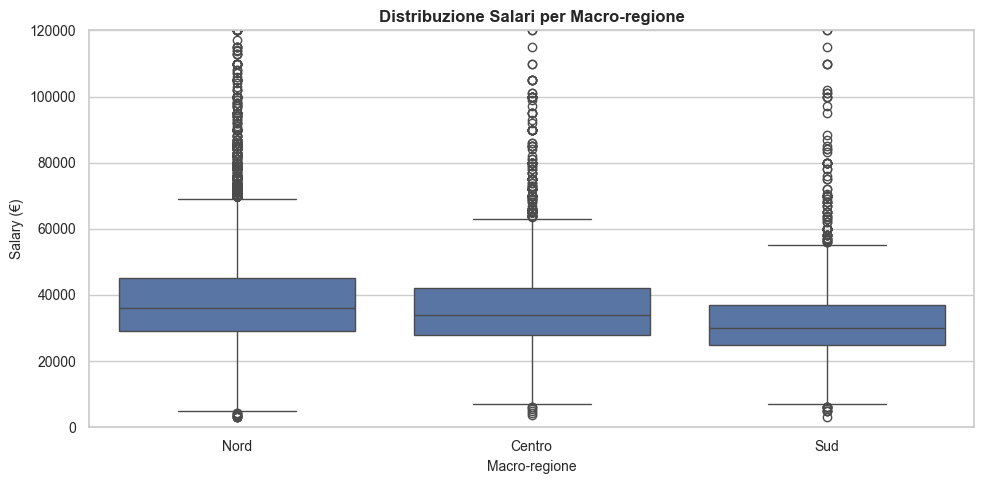

In [14]:
plot_salary_boxplot(
    data=df_filtered, x="macro_region", title="Distribuzione Salari per Macro-regione",
    xlabel="Macro-regione", order=["Nord", "Centro", "Sud"],
    figsize=(10, 5)
)

La Welch ANOVA conferma differenze **altamente significative** tra macro-regioni.

In [15]:
# Test statistici - Regione
nord_salaries = df_filtered.loc[df_filtered["macro_region"] == "Nord", "salary"]
centro_salaries = df_filtered.loc[df_filtered["macro_region"] == "Centro", "salary"]
sud_salaries = df_filtered.loc[df_filtered["macro_region"] == "Sud", "salary"]
region_groups = [nord_salaries, centro_salaries, sud_salaries]

# Verifica assunzioni
check_anova_assumptions(
    groups=region_groups, labels=["Nord", "Centro", "Sud"], label="Macro-regione vs Salary",
).print_report()
print()

# Welch ANOVA (non assume varianze omogenee)
anova_region = oneway_anova(groups=region_groups, label="Macro-regione vs Salary", equal_var=False)
print("Salari medi per macro-regione:")
print(f"Nord {nord_salaries.mean():,.0f} | Centro {centro_salaries.mean():,.0f} | Sud {sud_salaries.mean():,.0f}")
anova_region.print_report()

Verifica assunzioni - Macro-regione vs Salary
Normalità (Shapiro-Wilk, α=0.05):
  Nord (n=17734): W=0.7511, p=8.61e-66 - non normale
  Centro (n=5420): W=0.6881, p=2.82e-70 - non normale
  Sud (n=3323): W=0.4657, p=6.20e-72 - non normale
Omoschedasticità (Levene, α=0.05):
  F=35.75, p=3.12e-16 - varianze non omogenee
Raccomandazione: Normalità violata, ma tutti i gruppi hanno n >= 30: l'ANOVA è robusta per il Teorema del Limite Centrale. Varianze non omogenee: usare Welch ANOVA.

Salari medi per macro-regione:
Nord 39,338 | Centro 36,698 | Sud 32,728
Welch ANOVA - Macro-regione vs Salary
        F-statistic: 197.44
        P-value: 2.57e-84
        Differenze significative (α=0.05): True


Il test Tukey HSD mostra che **tutte le coppie** sono significativamente diverse

In [16]:
tukey_region = tukey_hsd(nord_salaries, centro_salaries, sud_salaries)
print(tukey_region)
print("0 = Nord | 1 = Centro | 2 = Sud")

Tukey's HSD Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)   2639.779     0.000  1996.968  3282.590
 (0 - 2)   6610.542     0.000  5827.647  7393.436
 (1 - 0)  -2639.779     0.000 -3282.590 -1996.968
 (1 - 2)   3970.763     0.000  3058.250  4883.275
 (2 - 0)  -6610.542     0.000 -7393.436 -5827.647
 (2 - 1)  -3970.763     0.000 -4883.275 -3058.250

0 = Nord | 1 = Centro | 2 = Sud


### Interpretazione - Regione  

Un professionista tech al Nord guadagna mediamente ~€7k in più rispetto a un collega al Sud con lo stesso ruolo. Tuttavia, questo dato va letto insieme al costo della vita: €39k a Milano e €32k a Catania possono avere un potere d'acquisto più simile di quanto il dato grezzo suggerisca.

> **Risposta alla Domanda 2:** *Dove conviene lavorare?* - Il divario Nord-Sud è confermato statisticamente anche nel tech. La Lombardia offre i salari più alti in assoluto (la **Valle d'Aosta** ha bassa affidabilità a causa dei pochi campioni), ma il vantaggio reale dipende dal costo della vita locale.

## 2.3 Ruolo

**Cosa si analizza:** si confrontano i salari tra diversi ruoli professionali, con focus sui ruoli data/AI.

**Perché:** non tutti i ruoli tech pagano allo stesso modo. Capire la gerarchia salariale aiuta nelle scelte di carriera.

**Quale test e come funziona:**

- **Kruskal-Wallis**: è l'alternativa *non parametrica* all'ANOVA. Invece di confrontare le medie, confronta i **ranghi** (cioè le posizioni dei valori una volta ordinati dal più basso al più alto). Perché usarlo al posto dell'ANOVA? Perché alcuni ruoli hanno pochi campioni e distribuzioni non normali. Kruskal-Wallis è più robusto in queste condizioni: non richiede che i dati seguano una distribuzione a campana e funziona bene anche con campioni piccoli.

Tra i ruoli data/AI: **Data Governance** svetta ma con pochi campioni.

In [17]:
role_groups = describe_groups(df=df_data, group_column="jobTitle", value_column="salary").sort_values(by="mean", ascending=False)
role_groups

,n,mean,std,min,median,max
jobTitle,,,,,,
data_governance,18,76961.11,74509.24,25000.0,57500.0,350000.0
Forward Deployed AI Engineer,1,64000.00,NaN,64000.0,64000.0,64000.0
genai_engineer,6,40833.33,12254.25,32000.0,35500.0,64000.0
ai_consultant,8,39600.00,15054.95,27000.0,34500.0,71000.0
data_scientist,1753,37990.98,14585.93,3000.0,35000.0,200000.0
data_engineer,1253,36441.48,10753.48,7200.0,34500.0,105000.0
ai_engineer,520,36083.45,24275.01,3000.0,33000.0,444600.0
Software AI Engineer,1,34800.00,NaN,34800.0,34800.0,34800.0
data_analyst,1842,34622.42,14821.38,3600.0,33000.0,345000.0


**AI Engineer** e **Data Analyst** sono i ruoli entry-level del settore.

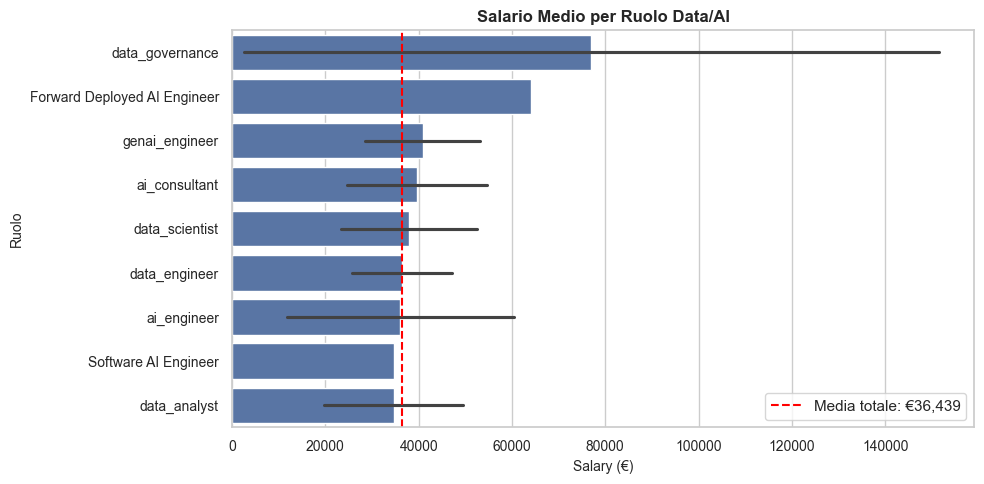

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df_data, x="salary", y="jobTitle", order=role_groups.index, errorbar="sd", ax=ax)
ax.axvline(x=df_data["salary"].mean(), color="red", linestyle="--", label=f"Media totale: €{df_data['salary'].mean():,.0f}")
ax.set_title("Salario Medio per Ruolo Data/AI")
ax.set_xlabel("Salary (€)")
ax.set_ylabel("Ruolo")
ax.legend()
plt.tight_layout()
plt.show()

Il test Kruskal-Wallis conferma differenze significative tra ruoli data/AI.

In [19]:
# Verifica assunzioni
data_roles = {"data_analyst", "data_engineer", "data_scientist", "ai_engineer", "data_governance"}
salary_by_role = []
role_labels = []
for role, group in df_data.groupby(by="jobTitle"):
    if role in data_roles:
        salary_by_role.append(group["salary"])
        role_labels.append(role)

assumptions_roles = check_anova_assumptions(
    groups=salary_by_role, labels=role_labels, label="Ruoli Data/AI vs Salary",
)
assumptions_roles.print_report()

Verifica assunzioni - Ruoli Data/AI vs Salary
Normalità (Shapiro-Wilk, α=0.05):
  ai_engineer (n=520): W=0.3463, p=2.37e-39 - non normale
  data_analyst (n=1842): W=0.5599, p=1.04e-55 - non normale
  data_engineer (n=1253): W=0.8980, p=4.70e-28 - non normale
  data_governance (n=18): W=0.6187, p=1.04e-05 - non normale
  data_scientist (n=1753): W=0.7897, p=7.92e-43 - non normale
Omoschedasticità (Levene, α=0.05):
  F=27.18, p=2.31e-22 - varianze non omogenee
Raccomandazione: Normalità violata con gruppi piccoli (data_governance (n=18)). Usare Kruskal-Wallis (alternativa non parametrica).


In [20]:
# Kruskal-Wallis (non parametrico)
anova_roles = oneway_anova(groups=salary_by_role, label="Ruoli Data/AI vs Salary", non_parametric=True)
anova_roles.print_report()

Kruskal-Wallis - Ruoli Data/AI vs Salary
        H-statistic: 94.60
        P-value: 1.38e-19
        Differenze significative (α=0.05): True


La differenza di salario tra il **Data Scientist** e il **Data Engineer** è statisticamente significativa.

In [21]:
# Test t: Data Scientist vs Data Engineer
ds_salaries = df_data.loc[df_data["jobTitle"] == "data_scientist", "salary"]
de_salaries = df_data.loc[df_data["jobTitle"] == "data_engineer", "salary"]

t_roles = ttest(group1=ds_salaries, group2=de_salaries, label_group1="Data Scientist", label_group2="Data Engineer")
t_roles.print_report()

Test t - Data Scientist vs Data Engineer
        Media Data Scientist: €37990.98 | Media Data Engineer: €36441.48
        t-statistic: 3.35, P-value: 8.11e-04
        Effect size (Cohen's d): 0.12


### Interpretazione - Ruolo  
La specializzazione paga. I ruoli di gestione e analisi avanzata hanno premium salariali rispetto ai ruoli più operativi.

## 2.4 Dimensione Azienda

**Cosa si analizza:** si confrontano i salari per dimensione aziendale e si analizza l'interazione con l'esperienza.

**Perché:** la narrativa comune dice "le grandi aziende pagano di più". Si verifica se è vero e se l'effetto cambia in base all'esperienza.

**Quale test e come funziona:**

- **ANOVA a due vie (two-way ANOVA)**: finora si è usata l'ANOVA "a una via" (un solo fattore). L'ANOVA a due vie analizza **due fattori contemporaneamente** e, cosa cruciale, la loro **interazione**. Cosa significa interazione? Un esempio: se le grandi aziende pagassero di più *solo* per i senior ma non per i junior, ci sarebbe un'interazione tra dimensione aziendale e esperienza. Se invece il premium delle grandi aziende fosse lo stesso per tutti i livelli, non ci sarebbe interazione (effetto additivo).

**Come leggere i risultati:** la tabella ANOVA a due vie riporta tre righe di interesse:
1. **Effetto principale del fattore 1** (es. esperienza): significativo se p < 0.05
2. **Effetto principale del fattore 2** (es. dimensione): significativo se p < 0.05
3. **Interazione** (fattore 1 × fattore 2): se p < 0.05, l'effetto di un fattore *dipende* dal livello dell'altro

**Nota sulle assunzioni:** i gruppi per dimensione aziendale derivano dal dataset filtrato completo. La tabella descrittiva mostra la numerosità di ogni gruppo, confermando l’applicabilità del TCL.

Le **grandi aziende** pagano leggermente di più (€40k delle corporate 5001+ vs €37k delle startup).

In [22]:
describe_groups(df=df_filtered, group_column="companySize", value_column="salary")

,n,mean,std,min,median,max
companySize,,,,,,
1-10,2777,36946.71,17955.75,4200.0,34000.0,470000.0
1001-5000,3988,37878.56,15794.30,3000.0,35000.0,360000.0
11-50,4329,37012.39,18220.55,3000.0,33000.0,500000.0
201-500,3429,37426.75,14864.84,5000.0,34000.0,310000.0
5001+,2326,40437.38,23358.71,8000.0,37000.0,460000.0
501-1000,2591,37448.42,17082.24,3000.0,34000.0,345000.0
51-200,5094,38132.41,17400.04,3000.0,35000.0,360000.0


La Welch ANOVA conferma differenze significative ma con **F-statistic basso**.

In [23]:
# Test statistici - Dimensione Azienda
salary_by_size = [group["salary"] for _, group in df_filtered.groupby(by="companySize")]

# Welch ANOVA (non assume varianze omogenee)
anova_size = oneway_anova(groups=salary_by_size, label="Dimensione azienda vs Salary", equal_var=False)
anova_size.print_report()

Welch ANOVA - Dimensione azienda vs Salary
        F-statistic: 8.06
        P-value: 1.05e-08
        Differenze significative (α=0.05): True


La differenza startup vs corporate è significativa ma con **effect size piccolo**.

In [24]:
# Test t: Startup vs Corporate
startup_salaries = df_filtered.loc[df_filtered["companySize"] == "1-10", "salary"]
corporate_salaries = df_filtered.loc[df_filtered["companySize"] == "5001+", "salary"]

t_size = ttest(group1=startup_salaries, group2=corporate_salaries, label_group1="Startup (1-10)", label_group2="Corporate (5001+)")
t_size.print_report()

Test t - Startup (1-10) vs Corporate (5001+)
        Media Startup (1-10): €36946.71 | Media Corporate (5001+): €40437.38
        t-statistic: -5.89, P-value: 4.04e-09
        Effect size (Cohen's d): -0.17


- L'**ANOVA a due vie** mostra che:
  - L'**esperienza** ha l'effetto dominante
  - La **dimensione azienda** ha effetto significativo ma minore
  - Non c'è **nessuna interazione significativa** tra i due fattori

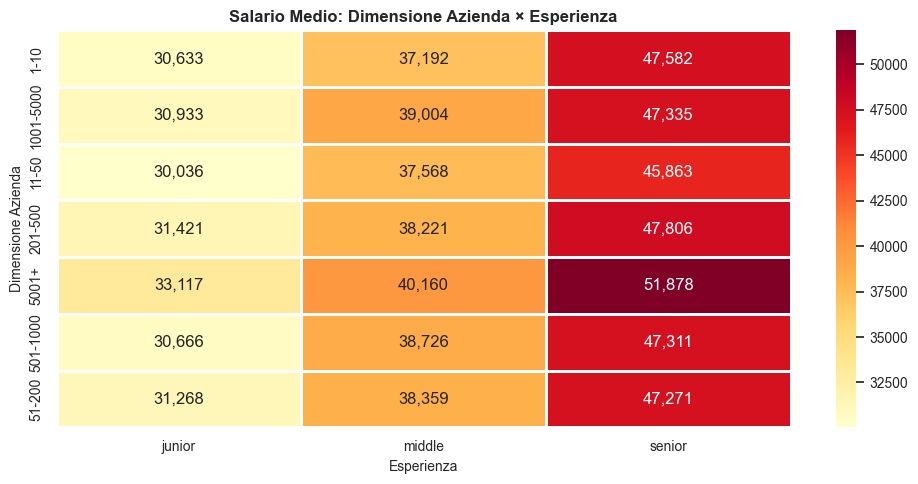

In [25]:
# Heatmap: Salary per Esperienza × Dimensione Azienda
pivot_heatmap = df_filtered.pivot_table(values="salary", index="companySize", columns="experience", aggfunc="mean")

plot_heatmap(
    data=pivot_heatmap[["junior", "middle", "senior"]],
    title="Salario Medio: Dimensione Azienda × Esperienza",
    xlabel="Esperienza", ylabel="Dimensione Azienda",
)

In [26]:
# ANOVA a due vie - Interazione Esperienza × Dimensione Azienda
anova_table = factorial_anova(data=df_filtered, target="salary", factors=["experience", "companySize"])
anova_table

,sum_sq,df,F,PR(>F)
C(experience),1.099006e+12,2.0,2057.65,0.0
C(companySize),2.193009e+10,6.0,13.69,0.0
C(experience):C(companySize),4.957026e+09,12.0,1.55,0.1
Residual,6.546272e+12,24513.0,NaN,NaN


Legenda: *PR(>F) < 0.05* = effetto significativo

### Interpretazione - Dimensione Azienda  
La scelta tra startup e corporate ha un impatto salariale modesto (~€3.5k, Cohen's d = 0.17). Se si sta valutando un'offerta, la dimensione dell'azienda non dovrebbe essere il fattore decisivo: conta molto di più il livello di esperienza e la localizzazione geografica. L'assenza di interazione conferma che questo vale per tutti i livelli di seniority.

## 2.5 Gender

**Cosa si analizza:** si misura il gender pay gap nel settore tech italiano, sia complessivo che stratificato per livello di esperienza.

**Perché:** si vuole rispondere alla domanda *"esistono disuguaglianze strutturali?"* Un semplice confronto delle medie non basta, è necessario controllare se il gap è un artefatto della diversa distribuzione di esperienza tra uomini e donne.

**Quale test e come funziona:**

- **Test t**: confronto diretto tra salari maschili e femminili, prima aggregato e poi stratificato per fascia di esperienza.
- **Cohen's d**: per quantificare la dimensione pratica del gap, non solo la significatività statistica.

**Perché l'analisi stratificata è fondamentale:** si immagini che il 70% delle donne nel campione sia junior e solo il 30% senior, mentre per gli uomini la distribuzione sia inversa. In questo caso, anche senza discriminazione salariale, le donne avrebbero una media più bassa semplicemente perché sono concentrate nei livelli meno pagati. L'analisi stratificata confronta uomini e donne *allo stesso livello di esperienza*, eliminando questo effetto composizione. Se il gap persiste anche all'interno di ogni fascia, allora c'è una componente strutturale.

In [27]:
# Gender Pay Gap Analysis
describe_groups(df=df_gender, group_column="gender", value_column="salary")

,n,mean,std,min,median,max
gender,,,,,,
female,3629,34511.66,14723.06,4000.0,32000.0,500000.0
male,22229,38465.75,18028.37,3000.0,35000.0,470000.0


Esiste un gap salariale significativo a favore degli uomini, con effect size piccolo.

In [28]:
# Test t
male_salaries = df_gender.loc[df_gender["gender"] == "male", "salary"]
female_salaries = df_gender.loc[df_gender["gender"] == "female", "salary"]
t_gender = ttest(group1=male_salaries, group2=female_salaries, label_group1="Male", label_group2="Female")
gap = t_gender.mean_group1 - t_gender.mean_group2
gap_pct = (gap / t_gender.mean_group2) * 100

print(f"Gender Pay Gap: €{gap:,.0f} ({gap_pct:.1f}%)")
print(f"T-Statistic: t = {t_gender.t_statistic:.2f}, P-value = {t_gender.p_value:.2e}, Cohen's d = {t_gender.cohens_d:.2f}")

Gender Pay Gap: €3,954 (11.5%)
T-Statistic: t = 14.50, P-value = 8.45e-47, Cohen's d = 0.22


#### Gender Pay Gap per livello di esperienza  
L'analisi stratificata per esperienza mostra che il gap **persiste a ogni livello di seniority**, anche dopo la correzione di Holm per i tre confronti multipli, quindi si tratta di una componente strutturale, non spiegabile solo dalla diversa distribuzione di esperienza. Inoltre, il gap tende a restare stabile o addirittura ad ampliarsi per i livelli senior, suggerendo che le dinamiche di promozione e negoziazione salariale penalizzano le donne nel lungo periodo.

In [29]:
gender_pvalues = {}
for experience in ("junior", "middle", "senior"):
    male_salaries = df_gender.loc[(df_gender["gender"] == "male") & (df_gender["experience"] == experience), "salary"]
    female_salaries = df_gender.loc[(df_gender["gender"] == "female") & (df_gender["experience"] == experience), "salary"]

    if male_salaries.shape[0] >= 5 and female_salaries.shape[0] >= 5:
        result = ttest(male_salaries, female_salaries, f"Male ({experience})", f"Female ({experience})")
        gender_pvalues[experience] = result.p_value
        gap = result.mean_group1 - result.mean_group2
        gap_pct = (gap / result.mean_group2) * 100

        print(f"{experience.upper()} (n_male={result.n_group1}, n_female={result.n_group2})")
        print(f"* Male: €{result.mean_group1:,.0f} | Female: €{result.mean_group2:,.0f}")
        print(f"* Gap = €{gap:,.0f} ({gap_pct:+.1f}%)")
        print(f"* T-Statistic = {result.t_statistic:.2f}, P-value = {result.p_value:.2e}, Cohen's d = {result.cohens_d:.2f}")
        print()

# Correzione di Holm sui 3 confronti
adjust_pvalues(gender_pvalues)

JUNIOR (n_male=8971, n_female=1767)
* Male: €31,273 | Female: €30,155
* Gap = €1,118 (+3.7%)
* T-Statistic = 2.88, P-value = 4.06e-03, Cohen's d = 0.09

MIDDLE (n_male=6880, n_female=1160)
* Male: €38,924 | Female: €36,079
* Gap = €2,845 (+7.9%)
* T-Statistic = 7.60, P-value = 4.48e-14, Cohen's d = 0.19

SENIOR (n_male=6378, n_female=702)
* Male: €48,089 | Female: €42,890
* Gap = €5,199 (+12.1%)
* T-Statistic = 8.63, P-value = 2.01e-17, Cohen's d = 0.24



,p_value,p_adjusted,is_significant
comparison,,,
junior,4.058614e-03,4.058614e-03,True
middle,4.479005e-14,8.958010e-14,True
senior,2.012482e-17,6.037447e-17,True


### Interpretazione - Gender Pay Gap  
Una donna nel tech italiano guadagna meno di un uomo anche quando ha la stessa esperienza, lavora nella stessa regione e in un'azienda di dimensioni comparabili. Il gap non è un artefatto statistico, è un segnale di disuguaglianza strutturale nel settore.

> **Risposta alla Domanda 3:** *Esistono disuguaglianze strutturali?* - Sì. Il gender pay gap è reale, persistente e non spiegabile interamente da differenze di esperienza o altri fattori osservabili. A questo si aggiunge il fenomeno del leaky pipeline (sezione Chi Quadro), che riduce la presenza femminile ai livelli senior.

## 2.6 Education

**Cosa si analizza:** si confrontano i salari per titolo di studio (diploma, laurea triennale, magistrale, PhD, etc.).

**Perché:** nel settore tech, l'istruzione formale è spesso considerata meno importante dell'esperienza pratica. I dati confermano questa percezione?

**Quale test e come funziona:** ANOVA one-way per confrontare le medie dei gruppi di istruzione. Se le differenze sono significative, significa che il titolo di studio ha un impatto misurabile sul salario - ma attenzione: potrebbe essere un effetto indiretto (chi ha un PhD tende ad avere più anni di esperienza).

In **mediana**, PhD (€40k) e laurea magistrale (€39k) guadagnano più di triennale (€36k) e diploma (€35.5k). Le medie sono distorte da pochi valori estremi (fino a €460k), e la variabilità intra-gruppo è alta: ci sono diplomati che guadagnano più di molti laureati

In [30]:
education_groups = describe_groups(df=df_education, group_column="educationType", value_column="salary")
education_groups

,n,mean,std,min,median,max
educationType,,,,,,
Bachelor's Degree,288,43797.78,42140.86,15615.0,36000.0,460000.0
High School,354,38938.49,15793.74,3500.0,35500.0,162000.0
Master's Degree,551,45272.81,33055.01,3000.0,39000.0,444600.0
Phd,40,42539.55,11407.86,28000.0,40000.0,78500.0


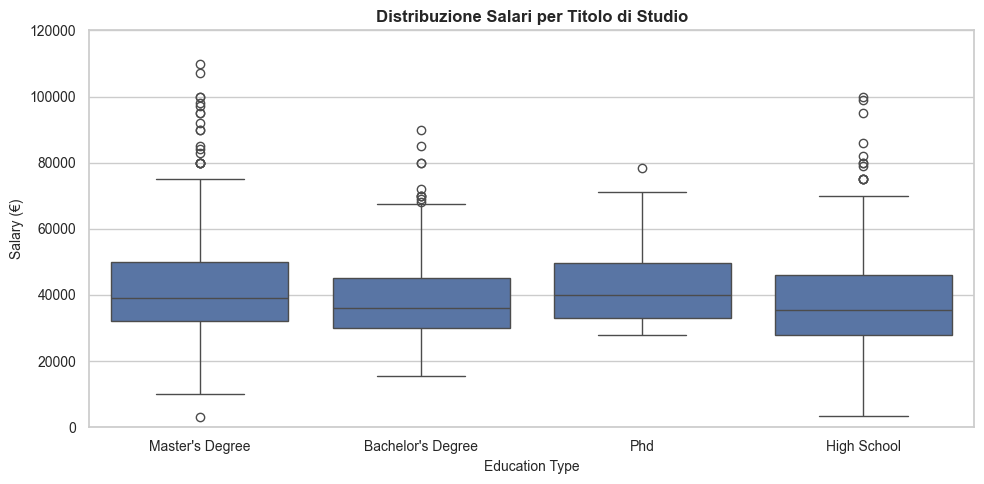

In [31]:
# Boxplot: Salary per Education Type
edu_order = education_groups["mean"].sort_values(ascending=False).index
plot_salary_boxplot(
    data=df_education, x="educationType", title="Distribuzione Salari per Titolo di Studio",
    xlabel="Education Type", order=edu_order,
    figsize=(10, 5)
)

Si verifica che le assunzioni per l'utilizzo dell'ANOVA siano rispettate. Tutti i gruppi hanno almeno 30 osservazioni, ma le distribuzioni hanno outlier estremi: si preferisce Kruskal-Wallis, che lavora sui ranghi ed è meno sensibile ai valori anomali.

Le differenze salariali per titolo di studio sono statisticamente significative.

In [32]:
# Verifica assunzioni
education_salary_groups = []
education_labels = []
for name, group in df_education.groupby(by="educationType"):
    education_salary_groups.append(group["salary"])
    education_labels.append(name)

assumptions_education = check_anova_assumptions(
    groups=education_salary_groups, labels=education_labels, label="Education vs Salary",
)
assumptions_education.print_report()

Verifica assunzioni - Education vs Salary
Normalità (Shapiro-Wilk, α=0.05):
  Bachelor's Degree (n=288): W=0.3246, p=3.43e-31 - non normale
  High School (n=354): W=0.8553, p=1.34e-17 - non normale
  Master's Degree (n=551): W=0.4434, p=4.63e-38 - non normale
  Phd (n=40): W=0.9118, p=4.29e-03 - non normale
Omoschedasticità (Levene, α=0.05):
  F=1.24, p=2.95e-01 - varianze omogenee
Raccomandazione: Normalità violata, ma tutti i gruppi hanno n >= 30: l'ANOVA è robusta per il Teorema del Limite Centrale.


In [33]:
# ANOVA: Education Type vs Salary
education_groups = [group["salary"] for _, group in df_education.groupby(by="educationType")]

result = oneway_anova(groups=education_groups, label="Education Type vs Salary" , non_parametric=True)
result.print_report()

Kruskal-Wallis - Education Type vs Salary
        H-statistic: 21.21
        P-value: 9.51e-05
        Differenze significative (α=0.05): True


### Interpretazione - Education  
Nel settore tech italiano il titolo di studio apre delle porte, ma non determina il salario in modo determinante. L'esperienza, il ruolo e la capacità di negoziazione contano di più. Un autodidatta con 5 anni di esperienza guadagna tipicamente più di un neolaureato magistrale.

## 2.7 Industry

**Cosa si analizza:** si confrontano i salari tra settori industriali, identificando quelli che pagano di più e di meno.

**Perché:** il settore in cui lavori può influenzare il salario tanto quanto il ruolo. Finance e consulting tech, ad esempio, tendono a pagare premium rispetto alla ricerca e alla pubblica amministrazione.

**Quale test:** test t tra il settore top e bottom (tra quelli con almeno 100 campioni) per quantificare la differenza e l'effect size.

Il settore di appartenenza crea differenze salariali significative: i settori finance e utilities pagano un premium rispetto ai settori più tradizionali.

In [34]:
industry_groups = describe_groups(df=df_data, group_column="companyIndustry", value_column="salary").query(expr="n >= 100").sort_values(by="mean", ascending=False)
industry_groups

,n,mean,std,min,median,max
companyIndustry,,,,,,
bancario,221,45359.94,35354.50,3000.0,41000.0,444600.0
assicurativo,148,42637.65,14168.00,9600.0,41500.0,136000.0
energia_utilities,208,40875.25,9351.82,10000.0,40000.0,70000.0
finanziario_altro,170,40024.71,14032.19,9500.0,39000.0,115000.0
sanita_pharma_biotech,138,39315.88,12655.93,10000.0,39500.0,86000.0
media_intrattenimento_editoria,107,39066.25,9933.66,12000.0,38000.0,73500.0
manifattura_generica,151,38083.93,9546.28,7200.0,37000.0,80000.0
altro_indeterminato,607,36921.31,15349.36,3000.0,34000.0,200000.0
tecnologia_ict,1613,34900.91,14978.93,3000.0,32000.0,345000.0


La differenza tra il settore più pagato e quello meno pagato (tra quelli con campioni sufficienti) è statisticamente significativa, con effect size medio

In [35]:
# Top industry vs Bottom industry - Test statistico
top_industry = industry_groups.index[0]
bottom_industry = industry_groups.index[-1]

top_salary = df_data.loc[df_data["companyIndustry"] == top_industry, "salary"]
bottom_salary = df_data.loc[df_data["companyIndustry"] == bottom_industry, "salary"]

ttest(top_salary, bottom_salary, label_group1=top_industry, label_group2=bottom_industry).print_report()

Test t - bancario vs istruzione_ricerca
        Media bancario: €45359.94 | Media istruzione_ricerca: €32416.36
        t-statistic: 5.06, P-value: 7.69e-07
        Effect size (Cohen's d): 0.44


### Interpretazione - Industry  
A parità di ruolo e esperienza, lavorare in un settore ad alto valore aggiunto (finance, big tech) può valere migliaia di euro in più all'anno. È un fattore da considerare nelle scelte di carriera, insieme alla qualità del lavoro e alle opportunità di crescita.

---
# 3. Analisi Incrociate

**Cosa si analizza:** si combinano i fattori analizzati singolarmente per capire come interagiscono tra loro.

**Perché:** le analisi univariate mostrano che esperienza, regione e dimensione aziendale contano singolarmente. Ma i loro effetti si sommano semplicemente, o si amplificano (o si annullano) a vicenda?

**Concetto chiave - l'interazione tra fattori:**
- **Nessuna interazione (effetto additivo):** il vantaggio di essere senior è lo stesso sia al Nord che al Sud. I fattori si sommano: senior + Nord = il meglio, junior + Sud = il peggio, ma il "bonus seniority" è costante.
- **Interazione presente:** il vantaggio di essere senior è *maggiore* al Nord che al Sud. In questo caso i fattori non si sommano semplicemente - l'effetto di uno dipende dal livello dell'altro.

Si risponde a tre domande specifiche:

1. **Dove conviene lavorare per ogni livello di esperienza?** → Heatmap Macro-regione × Esperienza
2. **Il gap Nord-Sud si amplifica con la seniority?** → Confronto stratificato con test statistici
3. **Qual è il peso relativo di ciascun fattore?** → ANOVA a tre vie (Esperienza × Regione × Dimensione Azienda)

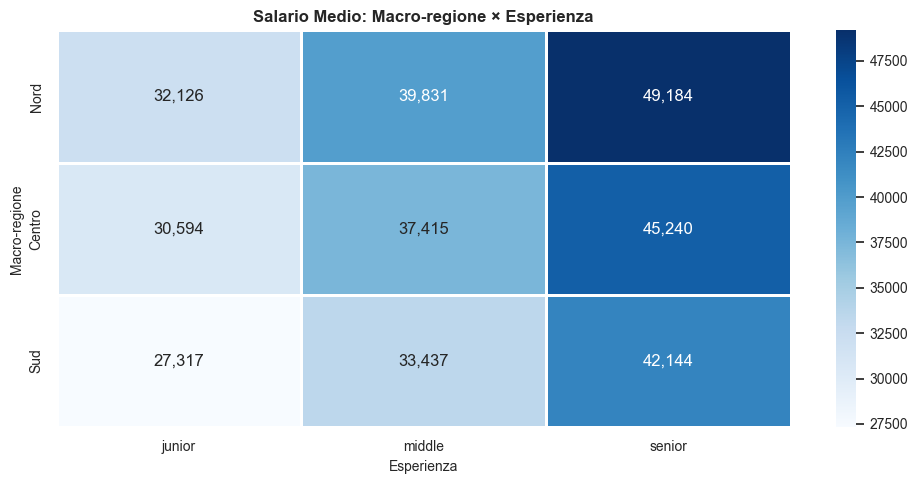

In [36]:
# Heatmap: Salary per Macro-regione × Esperienza
pivot_region_experience = df_filtered.pivot_table(values="salary", index="macro_region", columns="experience", aggfunc="mean")
pivot_region_experience = pivot_region_experience[["junior", "middle", "senior"]]
pivot_region_experience = pivot_region_experience.reindex(["Nord", "Centro", "Sud"])

plot_heatmap(
    data=pivot_region_experience,
    title="Salario Medio: Macro-regione × Esperienza",
    xlabel="Esperienza", ylabel="Macro-regione",
    cmap="Blues", figsize=(10, 5),
)

### Domanda 1: Dove conviene lavorare per ogni livello di esperienza?

**Lettura della heatmap:**
- Il **Nord** paga di più a tutti i livelli di esperienza, con un vantaggio in euro che cresce con la seniority
- La differenza Nord-Sud passa da ~€4.8k per i **junior** a ~€7k per i **senior**, ma in percentuale resta stabile (~17-19%)
- Il **Centro** si posiziona a metà strada, più vicino al Nord per i junior e più vicino al Sud per i senior

**Risposta:** Il Nord offre un premio salariale a ogni livello di esperienza. In euro il premio cresce con la seniority, ma in proporzione allo stipendio è simile per junior e senior.

### Domanda 2: Quanto conta la regione per un junior vs un senior?

Si confronta il gap salariale Nord vs Sud stratificando per livello di esperienza, per verificare se il divario geografico si amplifica con la seniority.

In [37]:
region_pvalues = {}
for experience in ("junior", "middle", "senior"):
    nord = df_filtered.loc[(df_filtered["experience"] == experience) & (df_filtered["macro_region"] == "Nord"), "salary"]
    sud = df_filtered.loc[(df_filtered["experience"] == experience) & (df_filtered["macro_region"] == "Sud"), "salary"]

    result = ttest(nord, sud, label_group1="Nord", label_group2="Sud")
    region_pvalues[experience] = result.p_value
    gap = result.mean_group1 - result.mean_group2
    gap_pct = (gap / result.mean_group2) * 100

    print(f"{experience.upper()}")
    print(f"* Nord: €{result.mean_group1:,.0f} (n={result.n_group1}) | Sud: €{result.mean_group2:,.0f} (n={result.n_group2})")
    print(f"* Gap = €{gap:,.0f} ({gap_pct:+.1f}%)")
    print(f"* P-value = {result.p_value:.2e}, Cohen's d = {result.cohens_d:.2f}", end="\n\n")

# Correzione di Holm sui 3 confronti
adjust_pvalues(region_pvalues)

JUNIOR
* Nord: €32,126 (n=7201) | Sud: €27,317 (n=1512)
* Gap = €4,809 (+17.6%)
* P-value = 1.25e-31, Cohen's d = 0.35

MIDDLE
* Nord: €39,831 (n=5535) | Sud: €33,437 (n=1019)
* Gap = €6,393 (+19.1%)
* P-value = 1.87e-49, Cohen's d = 0.43

SENIOR
* Nord: €49,184 (n=4998) | Sud: €42,144 (n=792)
* Gap = €7,040 (+16.7%)
* P-value = 1.42e-11, Cohen's d = 0.32



,p_value,p_adjusted,is_significant
comparison,,,
junior,1.254695e-31,2.509390e-31,True
middle,1.869405e-49,5.608216e-49,True
senior,1.416393e-11,1.416393e-11,True


### Interpretazione - Gap Nord-Sud stratificato

**Domanda 2: Quanto conta la regione per un junior vs un senior?**

Il gap Nord-Sud **cresce in euro con la seniority, ma non in percentuale**:
- **Junior**: ~€4.8k (+17.6%), Cohen's d = 0.35
- **Middle**: ~€6.4k (+19.1%), Cohen's d = 0.43
- **Senior**: ~€7.0k (+16.7%), Cohen's d = 0.32

Tutti e tre i confronti restano significativi dopo la correzione di Holm. Il divario è quindi *proporzionale* allo stipendio: il Nord paga circa il 17-19% in più a ogni livello, e poiché gli stipendi senior sono più alti, anche il gap in euro lo è. Le possibili cause includono maggiore competizione tra aziende tech al Nord, concentrazione di ruoli senior nelle sedi principali e differenze nel costo della vita.

### ANOVA a tre vie: Esperienza × Regione × Dimensione Azienda

**Domanda 3: Un senior al Sud guadagna più in una grande azienda o in una startup?**

L'ANOVA a tre vie permette di separare l'effetto di ciascun fattore controllando per gli altri:
- **Esperienza**: effetto dominante con la F-statistic più alta - conferma che la seniority è il predittore principale del salario
- **Macro-regione**: secondo fattore significativo - il divario geografico persiste anche controllando per esperienza e dimensione aziendale
- **Dimensione azienda**: effetto significativo ma minore rispetto ai primi due fattori
- **Interazioni**: l'interazione esperienza × regione è significativa ma piccola (F≈3.7, contro F≈2000 dell'esperienza): è il gap in euro che cresce con la seniority, visto sopra. L'interazione a tre vie è appena significativa (p≈0.02). Le interazioni che coinvolgono la dimensione aziendale non sono significative. In prima approssimazione i fattori agiscono in modo **additivo**

In [38]:
anova_3way = factorial_anova(
    data=df_filtered, target="salary", factors=["experience", "macro_region", "companySize"],
)
anova_3way

,sum_sq,df,F,PR(>F)
C(experience),1.070360e+12,2.0,2034.97,0.00
C(macro_region),9.427230e+10,2.0,179.23,0.00
C(companySize),2.457699e+10,6.0,15.58,0.00
C(experience):C(macro_region),3.927790e+09,4.0,3.73,0.00
C(experience):C(companySize),4.786581e+09,12.0,1.52,0.11
C(macro_region):C(companySize),1.920341e+09,12.0,0.61,0.84
C(experience):C(macro_region):C(companySize),1.051355e+10,24.0,1.67,0.02
Residual,6.435654e+12,24471.0,NaN,NaN


Legenda: *PR(>F) < 0.05* = effetto significativo

### Interpretazione - ANOVA a tre vie  
La dimensione aziendale incide poco. Un senior al Sud guadagna meno di un senior al Nord indipendentemente dalla dimensione dell'azienda. I fattori principali sono, in ordine: esperienza > regione > dimensione azienda.

---
# 4. Test di Indipendenza (Chi Quadro)

**Cosa si analizza:** si verifica se alcune variabili categoriche sono associate tra loro o indipendenti.

**Perché:** finora si è analizzato come i fattori influenzano il *salario* (variabile numerica). Ora ci si chiede: i fattori sono correlati *tra loro*? Ad esempio, il remote è più diffuso al Nord? Le donne sono sottorappresentate ai livelli senior?

**Come funziona il test Chi Quadro (χ²):**

1. **Tabella di contingenza**: si costruisce una tabella che incrocia le due variabili categoriche, contando quante osservazioni cadono in ogni combinazione (es. "remote + Nord", "onsite + Sud")
2. **Frequenze attese**: si calcolano le frequenze che ci aspetteremmo *se le due variabili fossero indipendenti* (cioè se il work mode non dipendesse dalla regione)
3. **Confronto**: il test misura quanto le frequenze osservate si discostano da quelle attese. Più grande è la differenza, più forte è l'associazione
4. **Risultato**: la statistica χ² e il p-value. Se p < 0.05, le due variabili **non** sono indipendenti - esiste un'associazione significativa

### Il remote è più diffuso in certe regioni?  

**Work Mode × Regione (significativo):**
- La distribuzione delle modalità di lavoro **dipende** dalla macro-regione
- Al **Nord** prevale l'hybrid (65% contro 58-61% di Centro e Sud)
- Il full **remote** è proporzionalmente più diffuso al **Centro** (26%) e al **Sud** (25%) che al Nord (21%)
- L'**onsite** è leggermente più frequente al Sud (17% contro 14-15%)

In [39]:
# Chi Quadro: Work Mode × Macro-regione
contingency_workmode_region = pd.crosstab(index=df_filtered["workMode"], columns=df_filtered["macro_region"])
contingency_workmode_region

macro_region,Centro,Nord,Sud
workMode,,,
hybrid,3277,11494,1929
onsite,749,2591,552
remote,1394,3649,842


In [40]:
chi2_workmode_region = chi2_test(var1=df_filtered["workMode"], var2=df_filtered["macro_region"], label="Work Mode × Macro-regione")
chi2_workmode_region.print_report()

Chi² - Work Mode × Macro-regione
        Chi² = 104.85, P-value = 9.13e-22, df = 4
        Associazione significativa: True


### Interpretazione - Work Mode × Regione

Le differenze sono statisticamente significative ma contenute. Il Nord, dove hanno sede molte aziende tech, è dominato dall'hybrid. Al Centro e al Sud il full remote è più diffuso, plausibilmente perché permette di lavorare da lì per aziende con sede altrove. Il dataset non permette però di verificare dove abbia sede l'azienda.

### La distribuzione di genere cambia con l'esperienza?  

**Gender × Esperienza (significativo):**
- La percentuale di donne **diminuisce** nei livelli di esperienza più alti
- Questo è il fenomeno del **"leaky pipeline"**: le donne abbandonano il settore tech con maggiore frequenza degli uomini nel corso della carriera

In [41]:
# Chi Quadro: Gender × Esperienza
contingency_gender_experience = pd.crosstab(index=df_gender["gender"], columns=df_gender["experience"])
contingency_gender_experience

experience,junior,middle,senior
gender,,,
female,1767,1160,702
male,8971,6880,6378


In [42]:
chi2_gender_experience = chi2_test(
    df_gender["gender"], df_gender["experience"], label="Gender × Esperienza",
)
chi2_gender_experience.print_report()

Chi² - Gender × Esperienza
        Chi² = 152.78, P-value = 6.68e-34, df = 2
        Associazione significativa: True


### Interpretazione - Gender × Esperienza

Il settore tech italiano non solo paga le donne meno (gender pay gap), ma le perde lungo il percorso. Meno donne ai livelli senior significa meno role model, meno mentorship femminile e un ciclo che si autoalimenta. Il gender pay gap aggregato è in parte influenzato da questa distribuzione sbilanciata - ma come mostrato nella Sezione 2.5, il gap persiste anche a parità di esperienza.

---
# 5. Regressione Multipla

**Si arriva al cuore dell'analisi.** Nelle sezioni precedenti si sono analizzati i fattori uno alla volta (o a coppie). Ma nella realtà, tutti i fattori agiscono simultaneamente. La regressione multipla permette di stimare l'effetto di ciascun fattore **controllando per tutti gli altri** - rispondendo così alla **Domanda 4**: *cosa fa davvero la differenza?*

Il modello OLS (Ordinary Least Squares) supera il limite delle analisi univariate, dove l'effetto di una variabile potrebbe essere confuso da correlazioni con altre.

**Perché `log(salary)`:** la distribuzione dei salari è fortemente asimmetrica (skewness ≈ 7), con pochi valori molto alti che influenzerebbero molto le stime. Il logaritmo riduce questa asimmetria e rende i coefficienti interpretabili come **variazioni percentuali**: un effetto del +5% vale sia per chi guadagna €30k sia per chi guadagna €60k.

**Variabili incluse:**
- `yearsOfExperience` (continua): ogni anno in più di esperienza contribuisce un incremento percentuale stimato
- `C(macro_region)`, `C(companySize)`, `C(workMode)`, `C(gender)` (categoriche): ogni livello viene confrontato con un baseline di riferimento

**Perché `experience` (junior/middle/senior) è esclusa:** la variabile categorica `experience` è derivata direttamente da `yearsOfExperience` (junior ≤ 2 anni, middle 3-5, senior > 5). Includerle entrambe nel modello causerebbe **multicollinearità**, distorcendo le stime dei coefficienti. Si mantiene la variabile continua perché cattura la relazione con maggiore granularità.

**Come leggere i risultati:**
- **R² (coefficiente di determinazione)**: indica la % di varianza salariale spiegata dal modello. Il restante è dovuto a fattori non inclusi (competenze specifiche, azienda, negoziazione, settore, etc.)
- **Coefficienti**: ogni coefficiente rappresenta la variazione stimata di log(salario) rispetto alla categoria di riferimento, a parità di tutte le altre variabili. La colonna `effect_pct` la converte in variazione percentuale: $(e^{\beta} - 1) \times 100$
- **Coefficiente positivo (verde)**: aumenta il salario previsto rispetto al baseline
- **Coefficiente negativo (rosso)**: diminuisce il salario previsto rispetto al baseline

Il modello OLS produce un summary completo con R², coefficienti e p-value per ogni variabile.

In [43]:
# Preparazione dati per regressione (incluso gender)
columns = ["salary", "yearsOfExperience", "macro_region", "companySize", "workMode", "gender"]
df_regression = df_gender.loc[:, columns].dropna()

# Regressione OLS su log(salary): i coefficienti si leggono come variazioni percentuali
formula = "np.log(salary) ~ yearsOfExperience + C(macro_region) + C(companySize) + C(workMode) + C(gender)"
ols_regression = ols(formula=formula, data=df_regression).fit()
ols_regression.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         np.log(salary)   R-squared:                       0.245
Model:                            OLS   Adj. R-squared:                  0.245
Method:                 Least Squares   F-statistic:                     648.8
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:40:06   Log-Likelihood:                -6173.6
No. Observations:               23995   AIC:                         1.237e+04
Df Residuals:                   23982   BIC:                         1.248e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
===============================================================================================
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      10.2344      0.009   1125.982      0.000      10.217      10.252
C(macro_region)[T.Nord]         0.0671      0.005     13.104      0.000       0.057       0.077
C(macro_region)[T.Sud]         -0.1065      0.007    -14.713      0.000      -0.121      -0.092
C(companySize)[T.1001-5000]     0.0307      0.008      3.908      0.000       0.015       0.046
C(companySize)[T.11-50]        -0.0164      0.008     -2.137      0.033      -0.032      -0.001
C(companySize)[T.201-500]       0.0259      0.008      3.200      0.001       0.010       0.042
C(companySize)[T.5001+]         0.0728      0.009      8.112      0.000       0.055       0.090
C(companySize)[T.501-1000]      0.0039      0.009      0.450      0.653      -0.013       0.021
C(companySize)[T.51-200]        0.0131      0.007      1.749      0.080      -0.002       0.028
C(workMode)[T.onsite]          -0.1452      0.006    -24.323      0.000      -0.157      -0.134
C(workMode)[T.remote]          -0.0027      0.005     -0.532      0.595      -0.013       0.007
C(gender)[T.male]               0.0757      0.006     12.926      0.000       0.064       0.087
yearsOfExperience               0.0322      0.000     75.420      0.000       0.031       0.033
==============================================================================
Omnibus:                     3212.927   Durbin-Watson:                   1.956
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            42941.663
Skew:                           0.039   Prob(JB):                         0.00
Kurtosis:                       9.553   Cond. No.                         55.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Coefficienti del modello (ordinati per impatto)

In [44]:
# Coefficienti più importanti (ordinati per valore assoluto)
# effect_pct = variazione percentuale del salario: (exp(coefficiente) - 1) * 100
df_coefficients = pd.DataFrame(
    data={
        "coefficient": ols_regression.params,
        "effect_pct": (np.exp(ols_regression.params) - 1) * 100,
        "std_err": ols_regression.bse,
        "p_value": ols_regression.pvalues,
    }
).round(decimals=4)

# Escludi intercept e ordina per coefficiente assoluto
df_coefficients = df_coefficients[df_coefficients.index != "Intercept"]
df_coefficients = df_coefficients.reindex(
    df_coefficients["coefficient"].abs().sort_values(ascending=False).index
)

df_coefficients.head(15)

,coefficient,effect_pct,std_err,p_value
C(workMode)[T.onsite],-0.1452,-13.5190,0.0060,0.0000
C(macro_region)[T.Sud],-0.1065,-10.1019,0.0072,0.0000
C(gender)[T.male],0.0757,7.8628,0.0059,0.0000
C(companySize)[T.5001+],0.0728,7.5545,0.0090,0.0000
C(macro_region)[T.Nord],0.0671,6.9418,0.0051,0.0000
yearsOfExperience,0.0322,3.2699,0.0004,0.0000
C(companySize)[T.1001-5000],0.0307,3.1132,0.0078,0.0001
C(companySize)[T.201-500],0.0259,2.6196,0.0081,0.0014
C(companySize)[T.11-50],-0.0164,-1.6307,0.0077,0.0326
C(companySize)[T.51-200],0.0131,1.3154,0.0075,0.0803


Il grafico mostra i coefficienti ordinati per impatto assoluto. Il colore indica la direzione: verde = positivo, rosso = negativo.

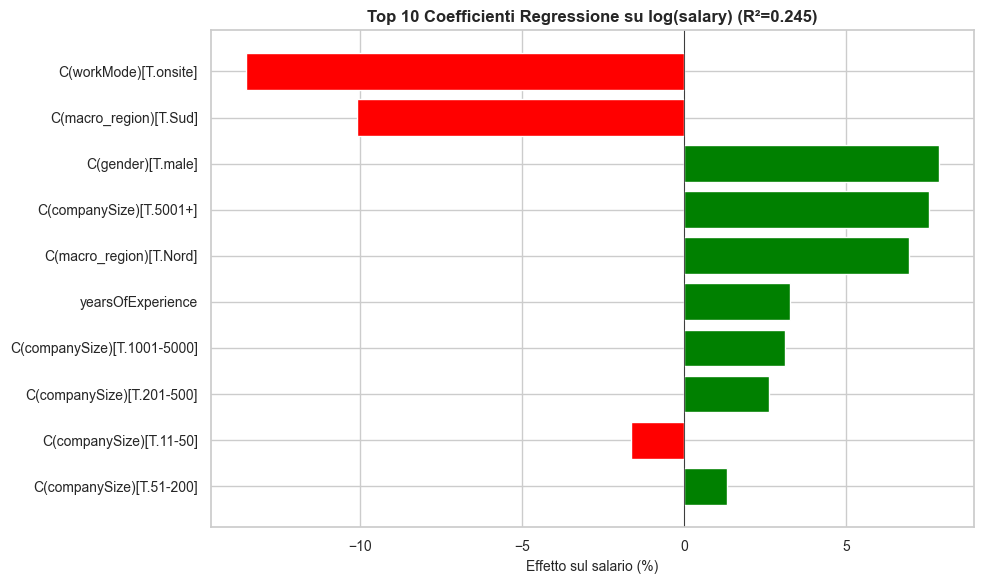

In [45]:
# Barplot: effetto percentuale dei coefficienti (top 10 per impatto)
coef_plot = df_coefficients.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["green" if x > 0 else "red" for x in coef_plot["effect_pct"]]
ax.barh(coef_plot.index, coef_plot["effect_pct"], color=colors)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_title(f"Top 10 Coefficienti Regressione su log(salary) (R²={ols_regression.rsquared:.3f})")
ax.set_xlabel("Effetto sul salario (%)")
plt.tight_layout()
plt.show()

### Interpretazione - Regressione Multipla

Il modello spiega circa il 25% della varianza di log(salario) (R² = 0.245): il resto dipende da fattori non osservati (ruolo, competenze, negoziazione, singola azienda).

**Effetti stimati, a parità delle altre variabili:**
1. **Anni di esperienza**: +3.3% per ogni anno. Su 10 anni di carriera l'effetto composto è di circa +38%, più di qualsiasi altro fattore
2. **Work mode**: chi lavora **onsite** guadagna circa il 13.5% in meno di chi lavora in hybrid; remote e hybrid sono equivalenti
3. **Macro-regione**: rispetto al Centro, il Nord paga circa il 7% in più e il Sud circa il 10% in meno
4. **Gender**: gli uomini guadagnano circa il 7.9% in più delle donne a parità di esperienza, regione, dimensione aziendale e work mode
5. **Dimensione azienda**: le corporate (5001+) pagano circa il 7.6% in più delle startup (1-10); le fasce intermedie hanno effetti piccoli

**Attenzione:** i coefficienti delle variabili categoriche dipendono dalla categoria di riferimento scelta e non sono direttamente confrontabili con quello di una variabile continua come gli anni di esperienza. L'ordinamento del grafico va letto come indicativo, non come una classifica rigorosa dell'importanza dei fattori.

> **Risposta alla Domanda 4:** *Cosa fa davvero la differenza?* - L'esperienza resta il fattore dominante sull'arco di una carriera. Tra i fattori categorici, lavorare onsite e lavorare al Sud sono associati alle penalità maggiori (circa -10/-14%), seguiti dal gender gap e dalla dimensione aziendale (circa 8%). A differenza di quanto suggerito dalle analisi univariate, il work mode non è un fattore trascurabile: è la modalità onsite a pesare, non il remote.

---
# 6. Riepilogo Finale

## Test Statistici Utilizzati

| Test | Quando usarlo | Variabili | In parole semplici |
|------|---------------|----------|---------------------|
| **t-test** | Confronto 2 gruppi | 1 categorica (2 livelli) + 1 continua | "Questi due gruppi sono davvero diversi?" |
| **ANOVA** | Confronto 3+ gruppi | 1 categorica (3+ livelli) + 1 continua | "Almeno uno di questi gruppi è diverso dagli altri?" |
| **Welch ANOVA / Welch t-test** | Come ANOVA / t-test, varianze diverse | Come ANOVA / t-test | "Come prima, ma senza assumere che i gruppi abbiano la stessa variabilità" |
| **Kruskal-Wallis** | ANOVA non parametrica | Come ANOVA, dati non normali | "Come ANOVA, ma più robusto con dati 'sporchi'" |
| **Tukey HSD** | Post-hoc dopo ANOVA | Confronti multipli a coppie | "OK sono diversi, ma *quali* coppie esattamente?" |
| **Correzione di Holm** | Più test sulla stessa domanda | p-value di una famiglia di test | "Con tanti test, qualcuno risulta significativo per caso: quali reggono?" |
| **Cohen's d** | Effect size | 2 gruppi | "La differenza è grande abbastanza da contare nella pratica?" |
| **Chi Quadro** | Indipendenza | 2 variabili categoriche | "Queste due categorie sono collegate tra loro?" |
| **Correlazione** | Relazione lineare | 2 variabili continue | "Quando una sale, l'altra sale (o scende) insieme?" |
| **Regressione OLS (log)** | Predizione multivariata | Multiple → log di 1 continua | "Di quanti punti percentuali cambia il salario per ciascun fattore, tenendo conto di tutti gli altri?" |

## Risultati Principali

1. **Esperienza** è il fattore dominante: +53% senior vs junior (d=0.96, Welch ANOVA F≈1900). La regressione stima +3.3% per ogni anno aggiuntivo di esperienza
2. **Divario Nord-Sud** confermato: gap ~€6.6k tra Nord e Sud, significativo a tutti i livelli di esperienza anche dopo la correzione di Holm. Il gap cresce in euro con la seniority ma resta stabile in percentuale (~17-19%)
3. **Ruolo**: Data Governance e Data Scientist hanno premium salariali rispetto a Data Engineer e Data Analyst
4. **Dimensione azienda**: impatto contenuto e additivo - nessuna interazione significativa con esperienza o regione (ANOVA a tre vie); le corporate 5001+ pagano circa il 7.6% in più delle startup a parità di altri fattori
5. **Gender pay gap**: 11.5% grezzo, circa 7.9% a parità di esperienza, regione, dimensione aziendale e work mode (regressione). Il gap persiste a ogni livello di seniority anche dopo la correzione di Holm
6. **Work mode**: chi lavora onsite guadagna circa il 13.5% in meno di chi lavora in hybrid a parità di altri fattori; remote e hybrid sono equivalenti
7. **Leaky pipeline**: la quota femminile scende dal 16.5% tra i junior al 9.9% tra i senior (Chi Quadro significativo)
8. **Industry**: settori finance/utilities pagano di più; gap significativo tra top e bottom industry

## Conclusioni

Tornando alle quattro domande iniziali:

1. **Quanto conta l'esperienza?** - È il fattore numero uno. Un senior guadagna oltre il 50% in più di un junior, e ogni anno di esperienza vale un incremento misurabile e significativo.

2. **Dove conviene lavorare?** - Il divario Nord-Sud esiste anche nel tech: il Nord paga circa il 17-19% in più del Sud a ogni livello di esperienza, quindi in euro il gap è maggiore per i senior. La Lombardia è la regione con i salari più alti (tra quelle con un campione consistente).

3. **Esistono disuguaglianze strutturali?** - Sì. Il gender pay gap persiste a ogni livello di esperienza. Non è solo un effetto composizione: anche a parità di seniority, regione, dimensione aziendale e work mode, le donne guadagnano circa l'8% in meno. A questo si aggiunge il fenomeno del leaky pipeline.

4. **Cosa fa davvero la differenza?** - L'esperienza, che sull'arco di 10 anni vale circa +38%. Tra gli altri fattori, lavorare onsite (-13.5%) e al Sud (-10% rispetto al Centro) sono associati alle penalità maggiori, seguiti da gender e dimensione aziendale (circa 8%). Il remote non comporta penalità rispetto all'hybrid.

### Limiti dell'analisi

- **Dati self-reported**: possibili bias di autoselezione e arrotondamento
- **Campione non rappresentativo**: il dataset riflette chi partecipa ai survey online, non l'intera popolazione tech italiana
- **Causalità**: le associazioni trovate non dimostrano relazioni causa-effetto (es. il remote non *causa* salari più alti)
- **Fattori non osservati**: competenze specifiche, certificazioni, capacità negoziale, dimensione della città - fattori che influenzano il salario ma non sono nel dataset